# B3 · Audit the current rules

How often do the anomaly rules the Forge app shipped fire during **normal racing**? Every alert on a clean lap
(B2) is a false alert, unless something really was wrong with the car.

**What's audited.** `pipeline/fw47_core/rules.py` is a line-for-line port of `src/services/anomalyDetection.js` and
`telemetryBaseline.js` (same thresholds, order and priority logic). `pipeline/tests/test_rules.py` ports the JS
tests, and checks that the vectorised versions used here give the same answers as the scalar port.

The app used the rules in two ways, and both are audited:

1. **Per sample:** one telemetry snapshot through `detectAnomalies()` (radio poller, Rovo `calculate-priority`).
2. **Per lap:** the Jira issue panel collapsed a lap into one snapshot (averages; maxima for brake/gear/DRS) and
   compared it with a baseline from the driver's previous two laps.

**The unit is an alert episode:** a run of consecutive samples of one car where the rule fires. Rates are episodes
per **car-hour of clean racing** (B2: 515 car-hours in 2024). The rules have no cooldown or dedupe, so the app
would have raised at least this many.

**Regulations.** Where rules touch the regulations (DRS), this uses the **2023–2025** rules only; 2026 changed them.
Data: 2024 in sections 1–7; section 8 repeats the headline numbers on 2023.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fw47_core.rules import TELEMETRY_RULES, rule_hits, lap_analysis

CLEAN = Path('..') / 'data' / 'clean'
RAW = Path('..') / 'data' / 'parquet'
SEASON = 2024
RULES = [r.incident_type for r in TELEMETRY_RULES]
PRIORITY = {r.incident_type: r.priority for r in TELEMETRY_RULES}
pd.set_option('display.max_columns', 30)

sessions = pd.read_parquet(RAW / 'sessions' / f'season={SEASON}' / 'sessions.parquet').set_index('session_key')
track = sessions['circuit_short_name']
keys = sorted(int(f.stem) for f in (CLEAN / 'samples' / f'season={SEASON}').glob('*.parquet'))
laps = pd.concat([pd.read_parquet(CLEAN / 'laps' / f'season={SEASON}' / f'{k}.parquet') for k in keys], ignore_index=True)
laps['track'] = laps['session_key'].map(track)
clean_hours = laps.loc[laps['clean'], 'lap_duration'].sum() / 3600
hours_by_track = laps[laps['clean']].groupby('track')['lap_duration'].sum() / 3600
print(f'{len(keys)} races, {clean_hours:.0f} clean car-hours')

24 races, 515 clean car-hours


## 1. Run every rule over every sample

In [2]:
COLS = ['session_key', 'driver_number', 'lap_number', 'date', 'speed', 'rpm', 'throttle', 'brake', 'n_gear', 'drs',
        'clean', 'in_lap', 'missing_duration', 'lap_distance_norm_m', 'x', 'y']
MAP_TRACKS = ['Monte Carlo', 'Monza', 'Sakhir']

episodes, fired, lap_mode, outlines, drs_runs = [], [], [], {}, []
for k in keys:
    s = pd.read_parquet(CLEAN / 'samples' / f'season={SEASON}' / f'{k}.parquet', columns=COLS)
    s = s[s['in_lap']].sort_values(['driver_number', 'date']).reset_index(drop=True)
    s['missing_duration'] = s['missing_duration'].astype(bool)
    s['track'] = track[k]
    h = rule_hits(s)
    starts = h & ~h.groupby(s['driver_number']).shift(fill_value=False)   # first sample of each episode
    run_id = (h != h.groupby(s['driver_number']).shift(fill_value=False)).cumsum()
    for r in RULES:
        e = s.loc[starts[r], ['track', 'driver_number', 'lap_number', 'clean', 'missing_duration', 'lap_distance_norm_m', 'date']]
        e['rule'] = r
        e['length'] = h.loc[h[r], r].groupby(run_id.loc[h[r], r]).size().to_numpy()
        episodes.append(e)
        f = s.loc[h[r] & s['clean'], ['track', 'lap_distance_norm_m', 'x', 'y']]
        fired.append(f.assign(rule=r) if track[k] in MAP_TRACKS else f[['track', 'lap_distance_norm_m']].assign(rule=r))
    if track[k] in MAP_TRACKS:
        c = s[s['clean']]
        one = c[(c.driver_number == c.driver_number.iloc[0]) & (c.lap_number == c.lap_number.iloc[0])]
        outlines[track[k]] = one[['x', 'y']]
    # DRS-failure episodes with surrounding samples, for section 5
    d = starts['drs-failure'] & s['clean']
    for i in s.index[d]:
        drs_runs.append(s.loc[i - 2:i + 3, ['track', 'driver_number', 'lap_number', 'date', 'speed', 'brake', 'drs']]
                        .assign(episode=len(drs_runs), offset=range(-2, -2 + len(s.loc[i - 2:i + 3]))))
    la = lap_analysis(s).merge(laps.loc[laps.session_key == k, ['driver_number', 'lap_number', 'clean']],
                               on=['driver_number', 'lap_number'])
    lap_mode.append(la.assign(track=track[k]))

episodes = pd.concat(episodes, ignore_index=True)
fired = pd.concat(fired, ignore_index=True)
lap_mode = pd.concat(lap_mode, ignore_index=True)
drs_runs = pd.concat(drs_runs, ignore_index=True)
print(f'{len(episodes):,} alert episodes in total')

215,348 alert episodes in total


## 2. False alerts per car-hour, per rule

On clean laps only. "Laps with an alert" is the share of clean laps where the rule fires at least once.

In [3]:
ce = episodes[episodes['clean']]
lap_hit = ce.drop_duplicates(['track', 'driver_number', 'lap_number', 'rule']).groupby('rule').size()
summary = pd.DataFrame({
    'priority': pd.Series(PRIORITY),
    'episodes on clean laps': ce.groupby('rule').size(),
    'per car-hour': ce.groupby('rule').size() / clean_hours,
    'per car per race (~1.5 h)': ce.groupby('rule').size() / clean_hours * 1.5,
    '% of clean laps with an alert': lap_hit / laps['clean'].sum() * 100,
    'median length (samples)': ce.groupby('rule')['length'].median(),
}).reindex(RULES).fillna(0)
summary.style.format({'episodes on clean laps': '{:,.0f}', 'per car-hour': '{:,.2f}', 'per car per race (~1.5 h)': '{:,.1f}',
                      '% of clean laps with an alert': '{:.1f}', 'median length (samples)': '{:.0f}'})

,priority,episodes on clean laps,per car-hour,per car per race (~1.5 h),% of clean laps with an alert,median length (samples)
emergency-braking,Critical,"82,974",161.25,241.9,99.4,2
engine-stall,Critical,0,0.00,0.0,0.0,0
gearbox-failure,Critical,0,0.00,0.0,0.0,0
drs-failure,Critical,747,1.45,2.2,3.2,1
power-unit,High,967,1.88,2.8,4.5,2
potential-issue,Medium,"76,952",149.55,224.3,99.5,5


In [4]:
total = ce.groupby('rule').size().sum() / clean_hours
print(f'All rules together: {total:,.0f} false alerts per car-hour, '
      f'i.e. ~{total * 1.5 * 20:,.0f} per race for a 20-car field.')

All rules together: 314 false alerts per car-hour, i.e. ~9,424 per race for a 20-car field.


## 3. By track (episodes per clean car-hour)

In [5]:
by_track = ce.groupby(['track', 'rule']).size().unstack(fill_value=0).reindex(columns=RULES, fill_value=0)
by_track = by_track.div(hours_by_track, axis=0).dropna(how='all').round(2)
by_track.style.background_gradient(axis=0, cmap='Reds').format('{:.2f}')

rule,emergency-braking,engine-stall,gearbox-failure,drs-failure,power-unit,potential-issue
track,,,,,,
Austin,151.27,0.00,0.00,0.42,0.00,213.56
Baku,100.89,0.00,0.00,0.85,0.08,275.28
Catalunya,163.50,0.00,0.00,0.79,0.00,61.55
Hungaroring,143.38,0.00,0.00,0.69,0.00,116.13
Imola,225.51,0.00,0.00,0.69,0.00,84.15
Jeddah,205.91,0.00,0.00,2.87,0.10,64.39
Las Vegas,159.28,0.00,0.00,2.19,0.00,211.87
Lusail,158.20,0.00,0.00,0.65,0.00,40.10
Melbourne,206.59,0.00,0.00,3.69,0.00,87.01


## 4. Where on track the rules fire

Clean-lap samples where each rule fires, on the track map (X/Y, from B2) for three different kinds of track, and
along the lap for all tracks.

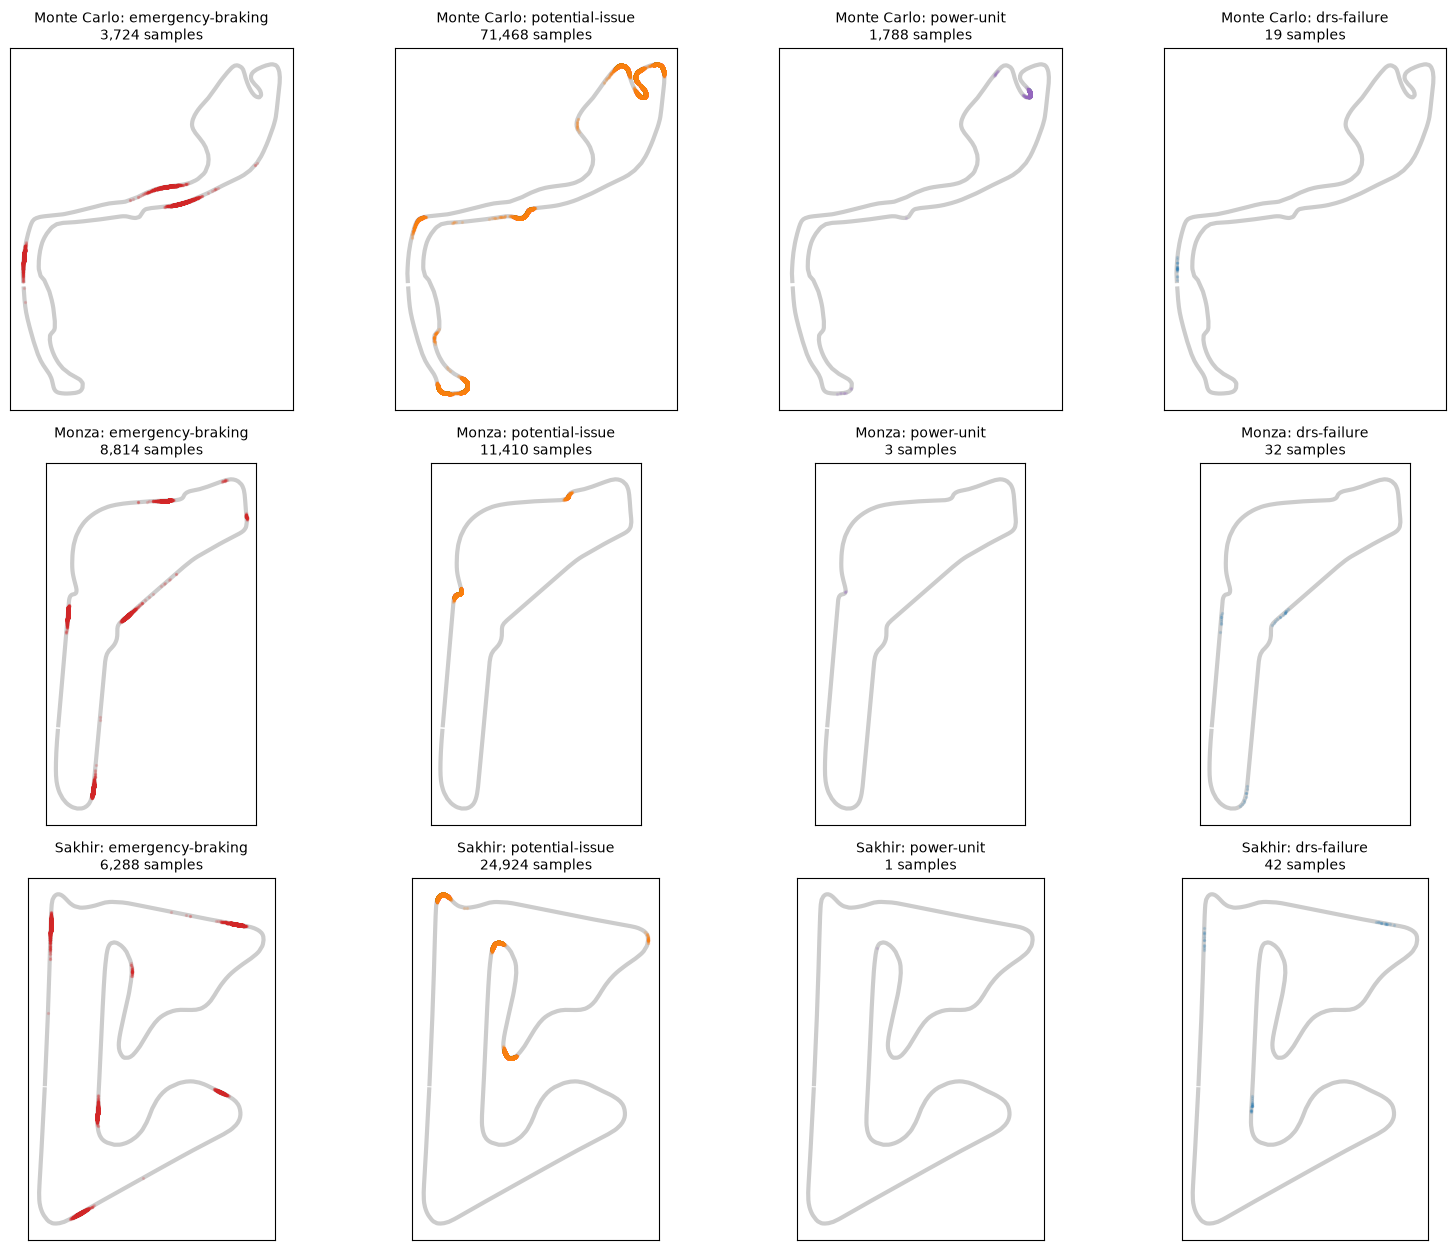

In [6]:
show = ['emergency-braking', 'potential-issue', 'power-unit', 'drs-failure']
colors = dict(zip(show, ['tab:red', 'tab:orange', 'tab:purple', 'tab:blue']))
fig, axes = plt.subplots(len(MAP_TRACKS), len(show), figsize=(16, 4.2 * len(MAP_TRACKS)))
for row, t in zip(axes, MAP_TRACKS):
    o = outlines[t]
    for ax, r in zip(row, show):
        ax.plot(o.x / 10, o.y / 10, color='0.8', lw=3, zorder=1)
        f = fired[(fired.track == t) & (fired.rule == r)].dropna(subset=['x'])
        ax.scatter(f.x / 10, f.y / 10, s=2, color=colors[r], alpha=.15, zorder=2)
        ax.set_title(f'{t}: {r}\n{len(f):,} samples', fontsize=10)
        ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()

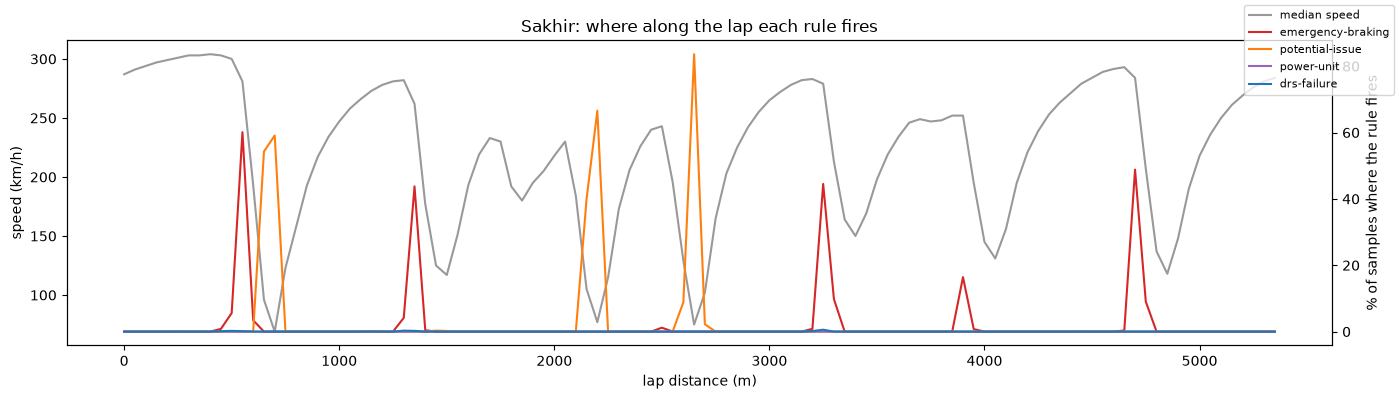

In [7]:
# Along the lap: share of clean-lap samples in each 50 m bin where the rule fires (Sakhir)
t = 'Sakhir'
k = int(sessions.index[track.eq(t)][0])
s = pd.read_parquet(CLEAN / 'samples' / f'season={SEASON}' / f'{k}.parquet',
                    columns=['clean', 'lap_distance_norm_m', 'speed', 'rpm', 'throttle', 'brake', 'n_gear', 'drs'])
s = s[s['clean']]
b = (s['lap_distance_norm_m'] // 50) * 50
rate = rule_hits(s).groupby(b).mean()
fig, ax1 = plt.subplots(figsize=(14, 4))
ax1.plot(s.groupby(b)['speed'].median(), color='0.6', label='median speed')
ax1.set_ylabel('speed (km/h)'); ax1.set_xlabel('lap distance (m)')
ax2 = ax1.twinx()
for r in show:
    ax2.plot(rate.index, rate[r] * 100, color=colors[r], label=r)
ax2.set_ylabel('% of samples where the rule fires')
fig.legend(loc='upper right', fontsize=8); ax1.set_title(f'{t}: where along the lap each rule fires')
plt.tight_layout()

## 5. Close look at each rule

### emergency-braking: `brake == 100 and speed > 250`
B1 showed `brake` is on/off: 100 means "pedal pressed", not "maximum braking". So the rule means "braking from
above 250 km/h", which every car does several times a lap at the end of each long straight (red dots on the maps
are the braking zones). It cannot tell an emergency from a normal braking point.

### potential-issue: `speed < 100 and throttle < 30`
Every slow corner. Monaco, Mexico City, Baku and Miami have the most.

### power-unit: `throttle == 0 and speed < 50 and rpm > 0`
Almost only at Monaco, where the hairpin is taken below 50 km/h off-throttle. Elsewhere it is rare in normal
racing, and it fires on the laps where cars actually stopped (below). This is the right *idea* (a car rolling
slowly without power) with the wrong *test*: a fixed speed can't distinguish a hairpin from a stricken car, but
"far below this track's normal speed at this point" (B4) can.

### engine-stall and gearbox-failure: impossible states
`rpm == 0` above 80 km/h, and neutral above 100 km/h with the engine running. **Zero episodes on 515 clean
car-hours.** On the laps where cars retired:

In [8]:
ret = episodes[episodes['missing_duration']]
pd.DataFrame({'on clean laps (515 car-hours)': ce.groupby('rule').size(),
              'on retirement laps (no lap time)': ret.groupby('rule').size()}).reindex(RULES).fillna(0).astype(int)

,on clean laps (515 car-hours),on retirement laps (no lap time)
rule,,
emergency-braking,82974,51
engine-stall,0,1
gearbox-failure,0,0
drs-failure,747,0
power-unit,967,124
potential-issue,76952,153


/tmp/ipykernel_70832/2172592491.py:4: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  s = s[(s.driver_number == e.driver_number) & s.date.between(e.date - pd.Timedelta(seconds=40), e.date + pd.Timedelta(seconds=30))]


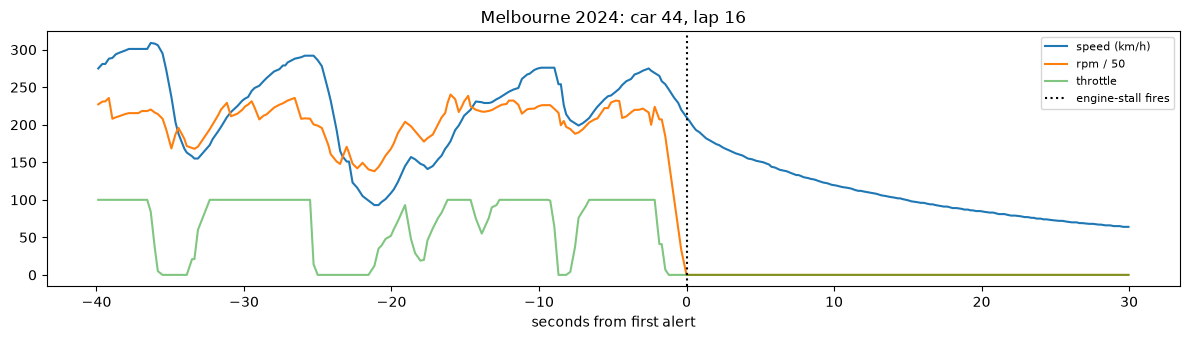

In [9]:
e = episodes[(episodes.rule == 'engine-stall') & episodes.missing_duration].iloc[0]
k = int(sessions.index[track.eq(e.track)][0])
s = pd.read_parquet(CLEAN / 'samples' / f'season={SEASON}' / f'{k}.parquet')
s = s[(s.driver_number == e.driver_number) & s.date.between(e.date - pd.Timedelta(seconds=40), e.date + pd.Timedelta(seconds=30))]
t0 = (s.date - e.date).dt.total_seconds()
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(t0, s.speed, label='speed (km/h)'); ax.plot(t0, s.rpm / 50, label='rpm / 50'); ax.plot(t0, s.throttle, label='throttle', alpha=.6)
ax.axvline(0, color='k', ls=':', label='engine-stall fires')
ax.set(xlabel='seconds from first alert', title=f'{e.track} {SEASON}: car {int(e.driver_number)}, lap {int(e.lap_number)}')
ax.legend(fontsize=8); plt.tight_layout()

That is Hamilton's engine failure at Melbourne 2024, lap 16: rpm drops to 0 while the car is still doing 210 km/h.
One real catch, no false alerts. That is exactly the profile of a rule worth keeping.

### drs-failure: `drs > 10 and brake == 100`
Under the 2023–2025 regulations the DRS flap may only be open in designated zones, and it closes automatically when
the driver brakes. Closing takes a moment, and car data arrives every ~0.24 s, so the **first braking sample at the
end of a DRS straight often still reads "open"**:

In [10]:
first = drs_runs[drs_runs.offset == 0]
before = drs_runs[drs_runs.offset == -1].set_index('episode')
after = drs_runs[drs_runs.offset == 1].set_index('episode')
lengths = episodes[(episodes.rule == 'drs-failure') & episodes.clean]['length']
print(f'{len(first)} episodes on clean laps')
print(f'previous sample had no braking: {(before.brake == 0).mean():.0%}')
print(f'DRS reads closed (0/8) on the next sample: {after.drs.isin([0, 8]).mean():.0%}')
lengths.value_counts().sort_index().rename('episodes').to_frame().T

747 episodes on clean laps
previous sample had no braking: 100%
DRS reads closed (0/8) on the next sample: 92%


length,1,2,3,4,6,7,9,13,15
episodes,700,32,6,2,1,3,1,1,1


So ~94% are a single sample: the flap closing as designed, seen a fraction of a second late. Requiring the flap to
stay open under braking for **3+ samples (~0.75 s)** removes those. DRS no longer exists from 2026, so this rule
only applies to 2023–2025 data.

Before B2 caught it, this check also turned up a **stuck brake channel**: at Zandvoort, car 23 shows brake = 100
for 9 s while accelerating from 216 to 334 km/h at full throttle. B2 now flags 4+ samples of brake = 100 at full
throttle as `q_brake_stuck` (89 runs in 2024, up to 22 s), and those samples are no longer clean.

In [11]:
long = episodes[(episodes.rule == 'drs-failure') & episodes.clean & (episodes.length >= 3)]
print(f'{len(long)} episodes of 3+ samples, {len(long) / clean_hours:.3f} per car-hour')
long[['track', 'driver_number', 'lap_number', 'length']].sort_values('length', ascending=False).head(10)

15 episodes of 3+ samples, 0.029 per car-hour


,track,driver_number,lap_number,length
86706,Spielberg,23,9,15
86705,Spielberg,23,6,13
124269,Monza,3,9,9
86709,Spielberg,23,9,7
86707,Spielberg,23,9,7
208177,Shanghai,77,4,7
124268,Monza,3,9,6
86708,Spielberg,23,9,4
86710,Spielberg,23,9,4
19534,Melbourne,18,5,3


Most of what remains is Albon at Spielberg, laps 6 and 9: DRS reads open (12) through the whole braking zone into
turn 3 and out of it. Either the status channel stuck or the flap stayed open; this data can't say which, but it is
the kind of event an impossible-state rule should surface.

## 6. The issue panel (per-lap mode)

For each lap the panel averaged speed, throttle and rpm, and took the **maximum** of brake, gear and DRS. Every lap
on which a driver braked has max brake = 100, and every lap with DRS used has max DRS ≥ 12, so `drs-failure` fires
on any lap where DRS was used. At Monza the lap-average speed is above 250 km/h, so `emergency-braking` fires too.

In [12]:
c = lap_mode[lap_mode['clean']]
panel = pd.crosstab(c['track'], c['priority'] + ' · ' + c['incidentType'].fillna('none'), normalize='index').mul(100).round(0)
print(f"clean laps rated Critical by the panel: {(c['priority'] == 'Critical').mean():.0%}")
panel

clean laps rated Critical by the panel: 29%


col_0,Critical · drs-failure,Critical · emergency-braking,Low · none
track,,,
Austin,20.0,0.0,80.0
Baku,31.0,0.0,69.0
Catalunya,25.0,0.0,75.0
Hungaroring,25.0,0.0,75.0
Imola,26.0,0.0,74.0
Jeddah,34.0,0.0,66.0
Las Vegas,26.0,0.0,74.0
Lusail,26.0,0.0,74.0
Melbourne,23.0,0.0,77.0


In [13]:
# The baseline comparison never fires: lap-average speed vs the spread of *individual samples* over two laps
z = (c['speed'] - c['base_avg']) / c['base_std']
print(f'z-score of lap-average speed vs baseline: median {z.median():.2f}, min {z.min():.2f} '
      f'(threshold -2); baseline sd median {c.base_std.median():.0f} km/h')

z-score of lap-average speed vs baseline: median 0.01, min -0.98 (threshold -2); baseline sd median 67 km/h


The pace-loss check compares a lap's *average* speed with the spread of individual samples on the previous two
laps (~67 km/h, the gap between a hairpin and a straight). A lap would have to be ~130 km/h slower on average to
trigger it, so it never fires. The panel's "Critical" verdicts were driven entirely by the DRS artefact above.

## 7. Decisions

| Rule | Priority | False alerts / car-hour | Decision | Why |
|---|---|---|---|---|
| emergency-braking | Critical | ~160 | **Replace** | `brake` is on/off, so this is "braked from > 250 km/h": every big braking zone. The B4 baseline (speed far below normal *for this point of the lap*) covers real emergencies. |
| engine-stall | Critical | 0 | **Keep** | Impossible state; no false alerts in either season; fired on 4 retirement laps (Hamilton's Melbourne 2024 engine failure, and three cars that stopped in 2023). |
| gearbox-failure | Critical | 0 | **Keep** | Impossible state; no false alerts on clean laps. One spurious hit in two seasons (a mid-shift neutral reading on lap 1, Jeddah 2023) and no real catch: cheap, but unproven. |
| drs-failure | Critical | ~1.5 | **Keep, with persistence** | Fires for one sample as the flap closes on braking (as designed). Require 3+ samples (~0.75 s): ~0.03 / car-hour. 2023–2025 only; there is no DRS from 2026. |
| power-unit | High | ~1.9 (mostly Monaco) | **Replace** | Right idea, wrong test: a fixed 50 km/h can't tell a hairpin from a stricken car. Becomes part of the B4 detector (slow *relative to this point on track*, no throttle). |
| potential-issue | Medium | ~150 | **Replace** | Every slow corner. Replaced by the B4 contextual baseline. |
| baseline (pace loss vs previous 2 laps) | Medium/High | 0 (never fires) | **Replace** | Compares a lap average with sample-level spread, so it can't fire. B4 compares speed per 25 m of lap distance instead. |
| lap summary (issue panel) | — | 29% of clean laps Critical | **Drop** | Max-of-lap DRS and brake turns normal laps into "DRS failure". |
| radio keywords | High | not audited | **Out of scope** | OpenF1 radio is audio only; there are no transcripts to test against. |

## 8. Does it hold in 2023?

Everything above is 2024. The same per-sample audit on 2023 (22 races), side by side with 2024, on clean laps:

In [14]:
def audit(season):
    """Per-sample rule episodes and per-lap panel verdicts for one season (sections 1, 2 and 6, condensed)."""
    trk = pd.read_parquet(RAW / 'sessions' / f'season={season}' / 'sessions.parquet').set_index('session_key')['circuit_short_name']
    ks = sorted(int(f.stem) for f in (CLEAN / 'samples' / f'season={season}').glob('*.parquet'))
    lp = pd.concat([pd.read_parquet(CLEAN / 'laps' / f'season={season}' / f'{k}.parquet') for k in ks], ignore_index=True)
    eps, panel_ = [], []
    for k in ks:
        s = pd.read_parquet(CLEAN / 'samples' / f'season={season}' / f'{k}.parquet', columns=COLS)
        s = s[s['in_lap']].sort_values(['driver_number', 'date']).reset_index(drop=True)
        s['missing_duration'] = s['missing_duration'].astype(bool)
        h = rule_hits(s)
        prev = h.groupby(s['driver_number']).shift(fill_value=False)
        run_id = (h != prev).cumsum()
        for r in RULES:
            e = s.loc[h[r] & ~prev[r], ['driver_number', 'lap_number', 'clean', 'missing_duration', 'date']]
            e['length'] = h.loc[h[r], r].groupby(run_id.loc[h[r], r]).size().to_numpy()
            eps.append(e.assign(rule=r, track=trk[k], session_key=k))
        panel_.append(lap_analysis(s).merge(lp.loc[lp.session_key == k, ['driver_number', 'lap_number', 'clean']],
                                            on=['driver_number', 'lap_number']))
    return dict(episodes=pd.concat(eps, ignore_index=True), panel=pd.concat(panel_, ignore_index=True),
                hours=lp.loc[lp['clean'], 'lap_duration'].sum() / 3600, races=len(ks))

seasons = {y: audit(y) for y in (2023, 2024)}
rows = {}
for y, a in seasons.items():
    ce_ = a['episodes'][a['episodes']['clean']]
    drs_ = ce_[ce_.rule == 'drs-failure']
    col = (ce_.groupby('rule').size() / a['hours']).reindex(RULES).fillna(0)
    col['all rules'] = len(ce_) / a['hours']
    col['drs-failure, 3+ samples'] = (drs_.length >= 3).sum() / a['hours']
    col['drs-failure: share of one sample'] = (drs_.length == 1).mean()
    col['issue panel: share of clean laps Critical'] = (a['panel'].loc[a['panel']['clean'], 'priority'] == 'Critical').mean()
    rows[f"{y} ({a['races']} races, {a['hours']:.0f} car-h)"] = col
pd.DataFrame(rows).round(3)

,"2023 (22 races, 473 car-h)","2024 (24 races, 515 car-h)"
rule,,
emergency-braking,156.608,161.252
engine-stall,0.000,0.000
gearbox-failure,0.000,0.000
drs-failure,1.669,1.452
power-unit,1.833,1.879
potential-issue,148.205,149.549
all rules,308.315,314.132
"drs-failure, 3+ samples",0.015,0.029
drs-failure: share of one sample,0.943,0.937


Rates are per clean car-hour, except the last two rows (shares). The impossible-state rules, everywhere they fired
in either season (clean or not), with the official result for that car:

In [15]:
res = pd.concat([pd.read_parquet(RAW / 'jolpica_results' / f'season={y}' / 'results.parquet') for y in seasons])
imp = pd.concat([a['episodes'].assign(season=y) for y, a in seasons.items()])
imp = imp[imp.rule.isin(['engine-stall', 'gearbox-failure'])]
# match on race day (all these races start and finish on the same UTC date)
dates = res.assign(race_date=res['race_date'].astype(str))
imp['race_date'] = imp['date'].dt.date.astype(str)
imp = imp.merge(dates[['season', 'race_date', 'driver_number', 'driver_code', 'laps', 'status']],
                on=['season', 'race_date', 'driver_number'], how='left')
imp[['season', 'track', 'driver_code', 'lap_number', 'rule', 'length', 'clean', 'missing_duration', 'laps', 'status']]

,season,track,driver_code,lap_number,rule,length,clean,missing_duration,laps,status
0,2023,Jeddah,DEV,1,gearbox-failure,4,False,False,50,Finished
1,2023,Spielberg,HUL,13,engine-stall,12,False,True,12,Retired
2,2023,Silverstone,MAG,32,engine-stall,5,False,True,31,Retired
3,2023,Singapore,OCO,43,engine-stall,6,False,True,42,Retired
4,2024,Melbourne,HAM,16,engine-stall,84,False,True,15,Retired


**The 2024 picture repeats almost exactly in 2023.** ~308 false alerts per car-hour (2024: ~314), the same two rules
at ~150 each, `power-unit` again almost only at Monaco, `drs-failure` again 94% single samples, and the issue
panel again rates ~28% of clean laps Critical.

`engine-stall` fired three times in 2023, each on the lap a car stopped (Hülkenberg at Spielberg, Magnussen at
Silverstone, Ocon at Singapore; Jolpica says only "Retired", not why), and never on a clean lap. Over two seasons
that is 4 of 4 on retirement laps and 0 false alerts in ~990 clean car-hours.

`gearbox-failure` fired once in two seasons: de Vries at Jeddah 2023, lap 1, where the gear channel reads neutral
for ~0.6 s at 190 km/h in the middle of a 5 → 2 downshift under braking. The car went on racing, so that is a false
alert, most likely a shift captured mid-change. It is outside the clean-lap rate (lap 1 is never clean) but a live
scorer would have raised it. Persistence of 3 samples would not remove it (it lasts 4); B6 can decide whether ~1
spurious alert in two seasons is acceptable for a rule that has yet to catch anything real.

## 9. Findings

**The shipped rules can't be used as an alerting system.** On 515 car-hours of clean 2024 racing they raise
**~314 alerts per car-hour**, roughly 9,400 per race for a 20-car field. Two rules account for nearly all of them,
each firing on **99% of clean laps**:
- `emergency-braking` (~161 / car-hour): `brake` is on/off, so "brake = 100 above 250 km/h" is every big braking zone.
- `potential-issue` (~150 / car-hour): "below 100 km/h, under 30% throttle" is every slow corner.

**It isn't a 2024 accident.** 2023 (22 races, 473 clean car-hours) gives ~308 false alerts per car-hour, the same
two rules at ~150 each, the same Monaco-only `power-unit`, 94% single-sample `drs-failure`, and 28% of clean laps
rated Critical by the issue panel.

**The impossible-state rules are good.** `engine-stall` and `gearbox-failure` never fire on clean laps in either
season (988 car-hours). `engine-stall` fired on Hamilton's engine failure at Melbourne 2024 (lap 16: rpm drops to 0
at 210 km/h) and on the laps where three cars stopped in 2023 (Hülkenberg, Spielberg; Magnussen, Silverstone; Ocon,
Singapore): 4 of 4 hits on retirement laps. `gearbox-failure` fired once in two seasons, on a lap-1 downshift at
Jeddah 2023 where the gear channel read neutral for ~0.6 s; the car carried on, so it was spurious.

**`drs-failure` is mostly a sampling artefact.** 94% of its 747 episodes are one sample: the first braking sample
after a DRS straight, before the flap reads closed (under the 2023–2025 rules it closes automatically on braking).
With a 3-sample (~0.75 s) persistence condition, 15 episodes remain (0.03 / car-hour; 7 in 2023, 0.015). Most are Albon at Spielberg
(laps 6 and 9), where DRS reads open through a whole braking zone and corner. From this data alone we can't tell a
stuck status channel from a flap that really stayed open, but surfacing it is what such a rule is for.

**`power-unit` is the right idea with the wrong test.** It fires mostly at the Monaco hairpin (37 / car-hour there,
~0.1 elsewhere), and 124 times on the laps where cars actually retired. A car rolling slowly with no throttle is
a real symptom, but "slow" has to mean "slow for this point of the track" (B4).

**The issue panel's verdicts were meaningless.** Collapsing a lap into maxima makes `drs-failure` fire on any lap
where DRS was used: **29% of clean laps rated Critical**. Its pace-loss baseline compares a lap *average* with
*sample-level* spread (~67 km/h), so it can never fire (the lowest z in 2024 was −0.98, against a threshold of −2).

**A data-quality issue found on the way:** the brake channel sometimes sticks at 100 while the car accelerates at full
throttle, for up to 22 s (89 runs in 2024). These caused the longest "DRS failure" and some "emergency braking" on
straights. Fixed in B2: `q_brake_stuck` marks 4+ samples of brake = 100 at full throttle, excluded from clean.

**Carried into B4–B6**
- Keep `engine-stall`, `gearbox-failure` and `drs-failure` (persistent, 2023–2025 only) as impossible-state rules.
- Replace `emergency-braking`, `power-unit`, `potential-issue` and the pace-loss baseline with the contextual
  baseline: speed against what is normal at this point of this track.
- The B6 target to beat: these rules' false-alert rate at the same detection rate. Their recall on real incidents
  needs the B5 labels.